# Zero-Shot Forecasting với Chronos-2 

In [33]:
import os
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from chronos import Chronos2Pipeline

# Cấu hình GPU
os.environ["CUDA_VISIBLE_DEVICES"] = "0"


In [34]:
# ========== 1. LOAD & CHUẨN BỊ DỮ LIỆU ĐA MÃ (MULTIVARIATE THỊ TRƯỜNG) ==========
df_final = pd.read_csv("../../data/processed/merged_data_final.csv")
df_final['timestamp'] = pd.to_datetime(df_final['timestamp'])

TARGET_COL = 'Close'
PREDICTION_LENGTH = 30
future_cols = ['is_derivative_exp', 'day_of_week', 'quarter', 'month']

# SỬA LỖI INFER_FREQ CHO TẤT CẢ CÁC MÃ BẰNG CÁCH RESAMPLE THEO TỪNG NHÓM
print("🔄 Đang Resample (B - Business Days) cho toàn bộ các mã cổ phiếu...")
dfs = []
for ticker_id, group in df_final.groupby('id'):
    g_resampled = group.set_index('timestamp').resample('B').ffill()
    g_resampled['id'] = ticker_id # Khôi phục cột id
    dfs.append(g_resampled.reset_index())
    
df_ticker = pd.concat(dfs, ignore_index=True)

# CHIA TẬP: Lấy 7 ngày cuối của MỖI MÃ ra làm Test, phần còn lại làm Context
df_context = df_ticker.groupby('id').apply(lambda x: x.iloc[:-PREDICTION_LENGTH]).reset_index(drop=True)
df_test_actual = df_ticker.groupby('id').apply(lambda x: x.iloc[-PREDICTION_LENGTH:]).reset_index(drop=True)

# Tập Future CHỈ chứa Known Future Covariates
df_future = df_test_actual[['id', 'timestamp'] + future_cols].copy()

print(f"📊 Tập Context (Quá khứ) gồm {len(df_context)} dòng. Gồm {df_context['id'].nunique()} mã cổ phiếu.")
print(f"🔮 Tập Future (Dự báo {PREDICTION_LENGTH} ngày tới) gồm {len(df_future)} dòng.")
display(df_future.head(3))

🔄 Đang Resample (B - Business Days) cho toàn bộ các mã cổ phiếu...
📊 Tập Context (Quá khứ) gồm 12704 dòng. Gồm 6 mã cổ phiếu.
🔮 Tập Future (Dự báo 30 ngày tới) gồm 180 dòng.


C:\Users\admin\AppData\Local\Temp\ipykernel_25484\4227191356.py:20: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_context = df_ticker.groupby('id').apply(lambda x: x.iloc[:-PREDICTION_LENGTH]).reset_index(drop=True)
C:\Users\admin\AppData\Local\Temp\ipykernel_25484\4227191356.py:21: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_test_actual = df_ticker.groupby('id').apply(lambda x: x.iloc[-PREDICTION_LENGTH:]).r

,id,timestamp,is_derivative_exp,day_of_week,quarter,month
0,FPT,2025-11-20,1,3,4,11
1,FPT,2025-11-21,0,4,4,11
2,FPT,2025-11-24,0,0,4,11


In [35]:
# ========== 2. LOAD MÔ HÌNH CHRONOS-2 ==========
print("\n🔄 Đang tải mô hình Chronos-2...")

pipeline = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map="cuda",  # Đổi thành "cpu" nếu không có GPU
    torch_dtype=torch.bfloat16,
)

print("✅ Mô hình Chronos-2 đã load thành công!")


🔄 Đang tải mô hình Chronos-2...
✅ Mô hình Chronos-2 đã load thành công!


In [37]:
# ========== 3. DỰ BÁO ZERO-SHOT CÓ COVARIATES + HỌC CHÉO KIỂU MỚI ==========
print(f"🔮 Đang chạy dự báo Zero-shot cho TẤT CẢ {df_context['id'].nunique()} mã cổ phiếu cùng lúc...")
print("💡 TÍNH NĂNG ĐƯỢC BẬT: Xử lý Vĩ mô (Past Covariates) + Cross-Learning (Học chéo quy luật giữa các mã)")

# Bật cross_learning=True với batch_size=100 theo khuyến nghị của Amazon 
# (Mô hình sẽ chia sẻ context giữa tất cả các cổ phiếu trong thị trường để dự báo chung)
forecast_df = pipeline.predict_df(
    df=df_context,
    future_df=df_future,
    prediction_length=PREDICTION_LENGTH,
    quantile_levels=[0.1, 0.5, 0.9],
    id_column="id",
    timestamp_column="timestamp",
    target=TARGET_COL,
    cross_learning=True,
    batch_size=100
)

print("\n📈 KẾT QUẢ DỰ BÁO TỐNG HỢP CÁC MÃ:")
forecast_result = forecast_df[['id', 'timestamp', 'predictions', '0.1', '0.9']]
display(forecast_result.head(14)) # Hiển thị 2 mã đầu tiên (mỗi mã 7 ngày) ))

🔮 Đang chạy dự báo Zero-shot cho TẤT CẢ 6 mã cổ phiếu cùng lúc...
💡 TÍNH NĂNG ĐƯỢC BẬT: Xử lý Vĩ mô (Past Covariates) + Cross-Learning (Học chéo quy luật giữa các mã)

📈 KẾT QUẢ DỰ BÁO TỐNG HỢP CÁC MÃ:


,id,timestamp,predictions,0.1,0.9
0,FPT,2025-11-20,96.5,93.5,99.0
1,FPT,2025-11-21,96.0,93.0,99.5
2,FPT,2025-11-24,96.0,92.5,99.5
3,FPT,2025-11-25,96.5,92.0,99.5
4,FPT,2025-11-26,96.5,91.5,100.5
5,FPT,2025-11-27,96.5,90.5,101.0
6,FPT,2025-11-28,96.5,90.5,102.0
7,FPT,2025-12-01,96.0,90.5,102.0
8,FPT,2025-12-02,96.5,90.5,102.5
9,FPT,2025-12-03,96.5,90.0,102.5


In [ ]:
# ========== 4. ĐÁNH GIÁ TỔNG MỨC ĐỘ CHUẨN XÁC TRÊN DOÀN THỊ TRƯỜNG ==========

# Hợp nhất dự báo và giá thực tế chung vào một Dataframe
merged_evaluate = pd.merge(
    forecast_result, 
    df_test_actual[['id', 'timestamp', 'Close']], 
    on=['id', 'timestamp'], 
    how='inner'
)

metrics_list = []

# Lặp qua từng mã để đo lường độ phân kỳ chuẩn xác (Forecast vs Actual)
for ticker, group in merged_evaluate.groupby('id'):
    y_pred = group['predictions'].values
    y_true = group['Close'].values
    
    mae = np.mean(np.abs(y_pred - y_true))
    rmse = np.sqrt(np.mean((y_pred - y_true) ** 2))
    mape = np.mean(np.abs((y_pred - y_true) / y_true)) * 100
    
    metrics_list.append({
        'Mã CK': ticker,
        'MAE (VND)': round(mae, 4),
        'RMSE': round(rmse, 4),
        'MAPE (%)': round(mape, 2)
    })

metrics_df = pd.DataFrame(metrics_list)
display(metrics_df)

print("\n" + "="*70)
print("📋 ĐIỂM SỐ TRUNG BÌNH TOÀN THỊ TRƯỜNG (ZERSHOTO ZERO-SHOT MODELS):")
print("="*70)
print(f"  • MAE Trung bình :  {metrics_df['MAE (VND)'].mean():.4f} VND")
print(f"  • RMSE Trung bình:  {metrics_df['RMSE'].mean():.4f} VND")
print(f"  • MAPE Trung bình:  {metrics_df['MAPE (%)'].mean():.2f}%")

📊 Đang tính toán Metrics lỗi cho từng mã cổ phiếu...



,Mã CK,MAE (VND),RMSE,MAPE (%)
0,FPT,1.6779,2.0408,1.76
1,HPG,1.0650,1.1369,4.01
2,SSI,1.5871,1.8189,5.37
3,VCB,1.8833,2.0696,3.28
4,VHM,9.8900,12.4252,8.91
5,VNM,1.7167,2.0204,2.71



📋 ĐIỂM SỐ TRUNG BÌNH TOÀN THỊ TRƯỜNG (ZERSHOTO ZERO-SHOT MODELS):
  • MAE Trung bình :  2.9700 VND
  • RMSE Trung bình:  3.5853 VND
  • MAPE Trung bình:  4.34%


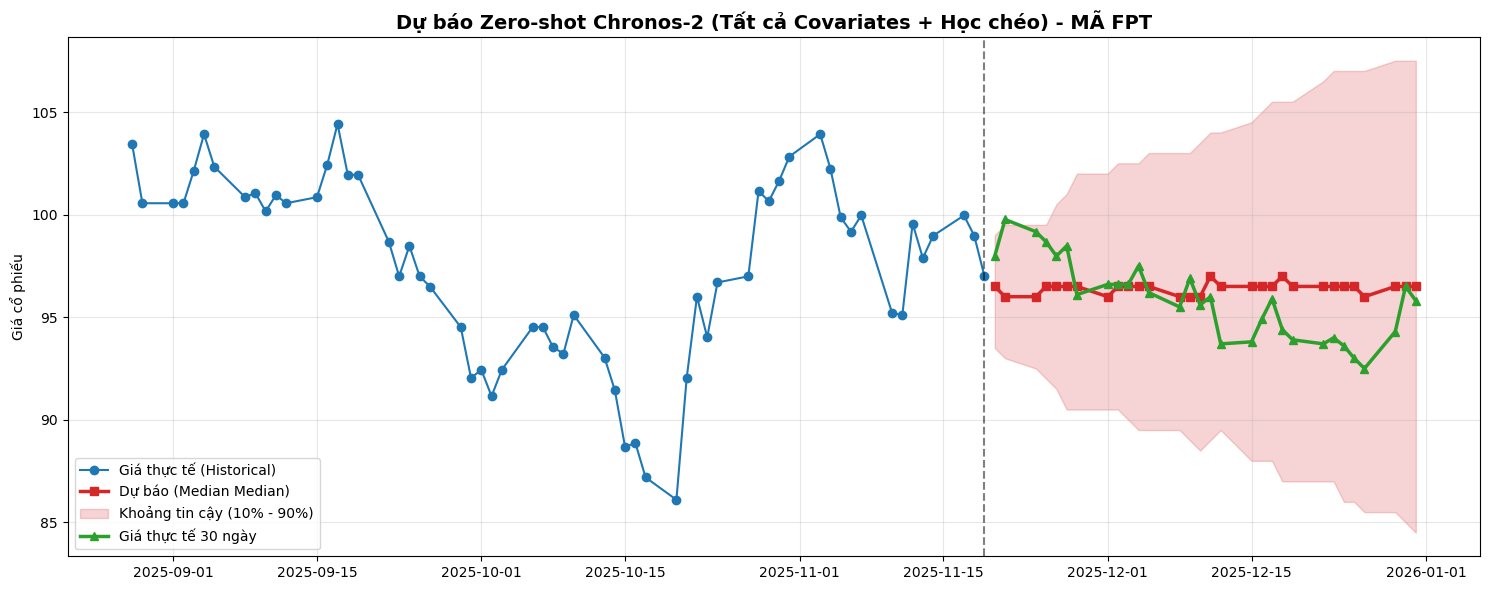

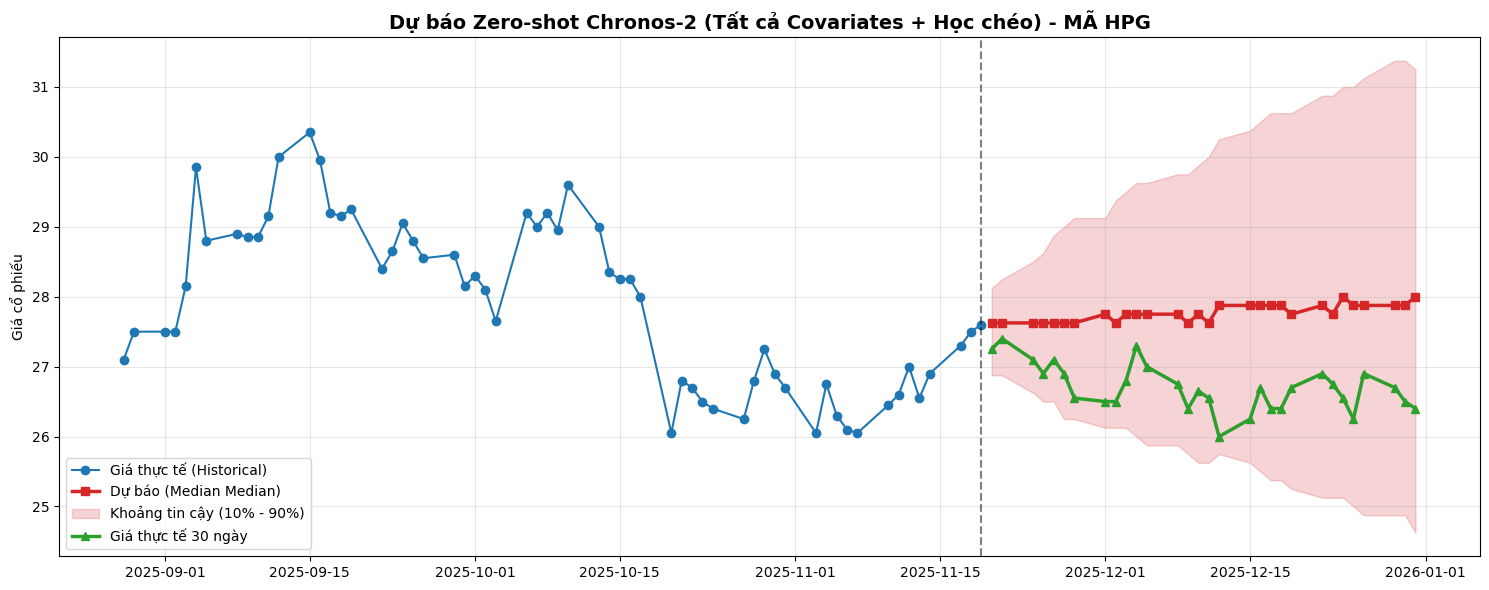

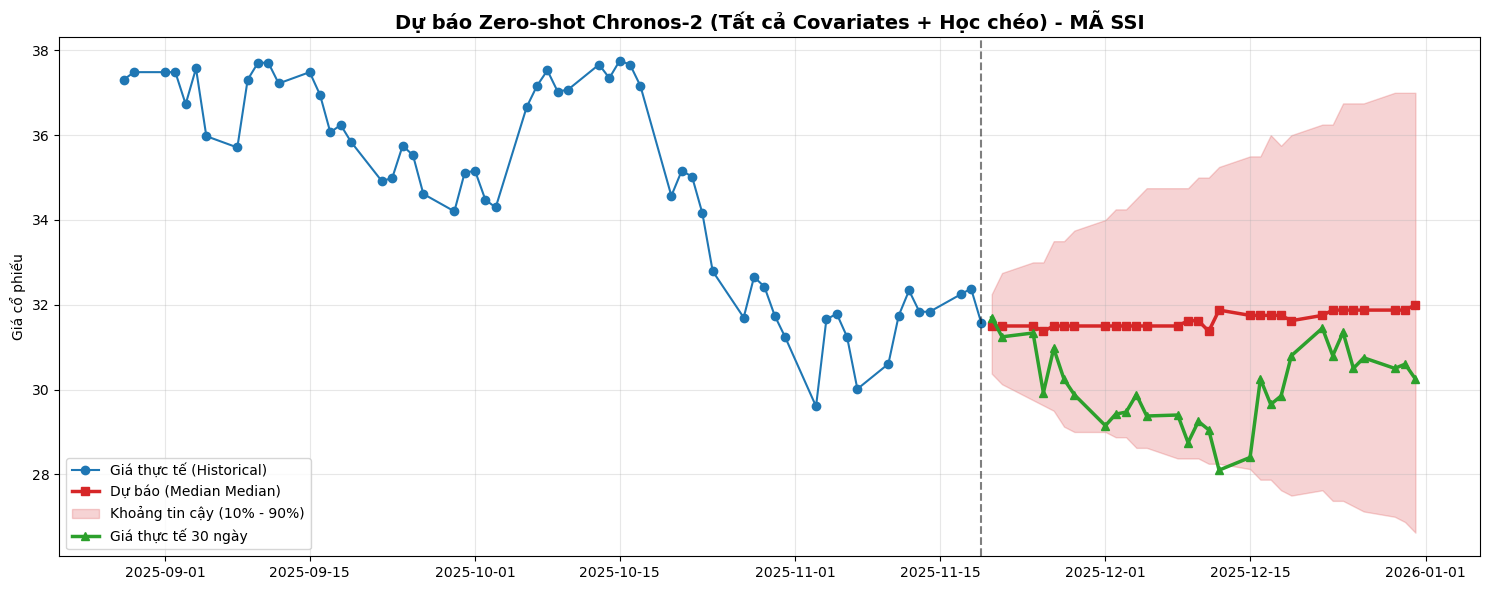

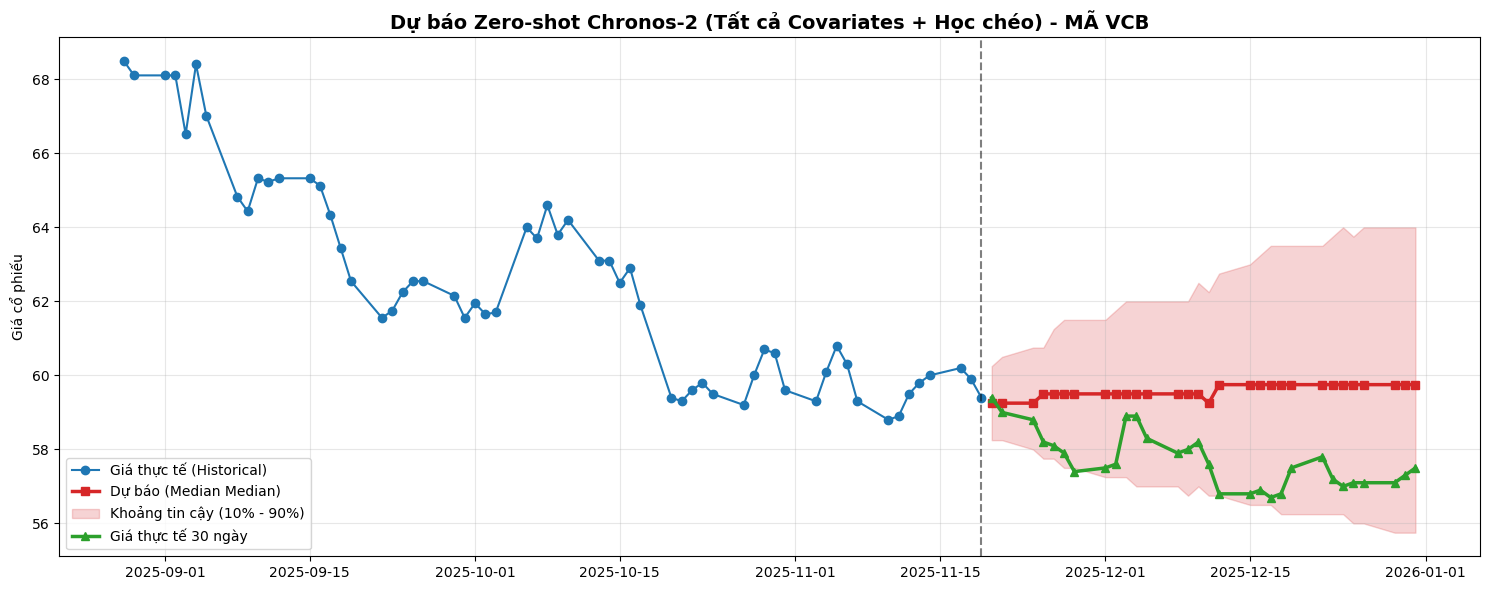

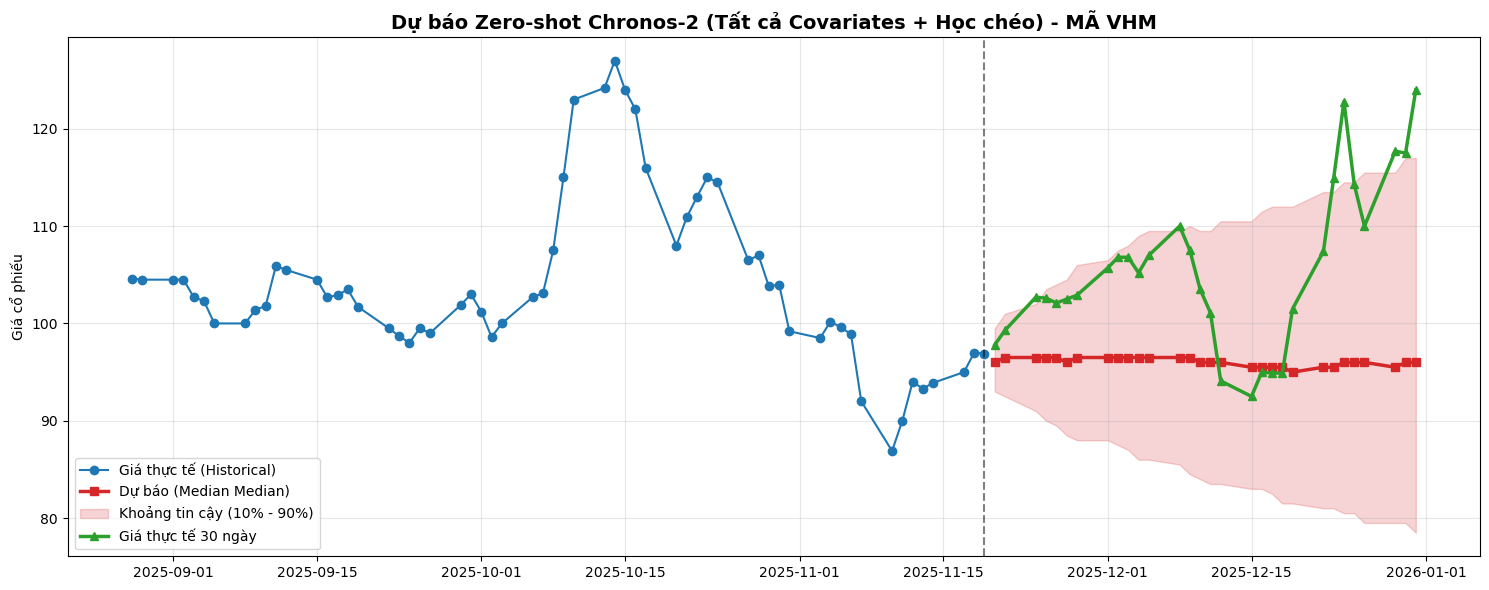

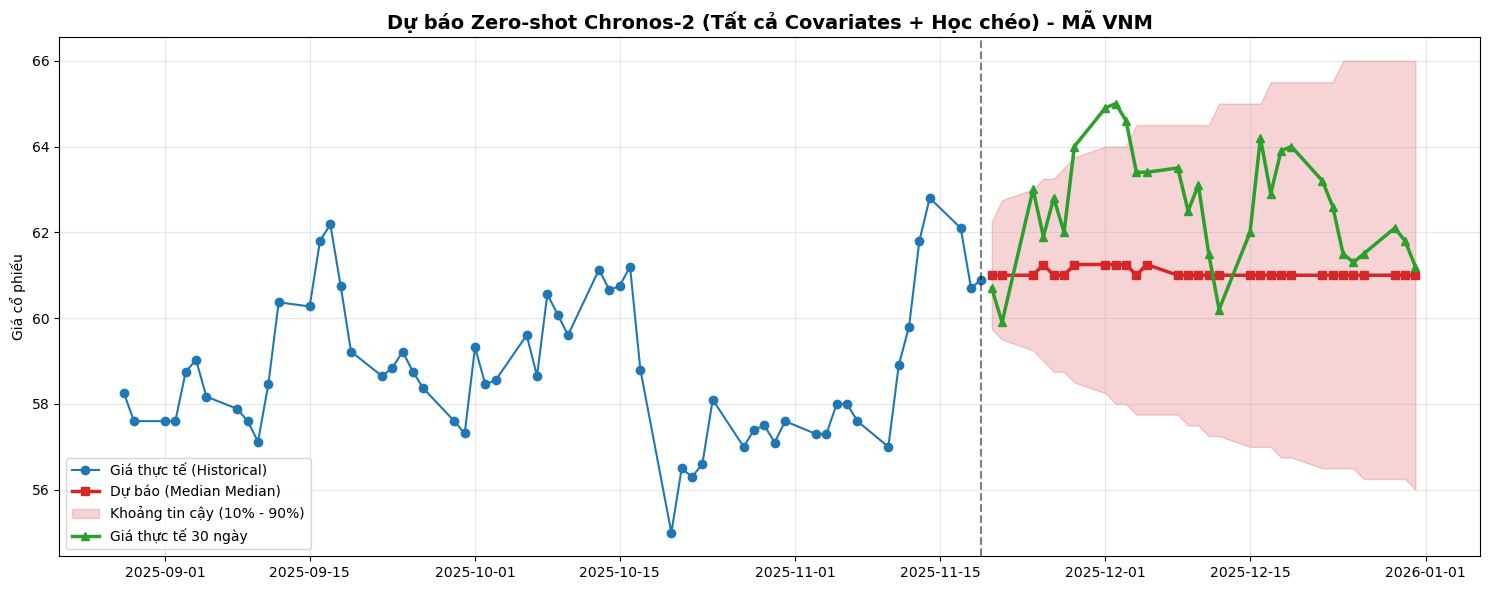

In [40]:
# ========== 5. VẼ BIỂU ĐỒ MINH HỌA MỘT SỐ MÃ TIÊU TÍNH ==========
import matplotlib.pyplot as plt

def plot_ticker_forecast(ticker_name):
    # Lấy 60 ngày lịch sử gần nhất làm mốc biểu diễn
    ticker_hist = df_context[df_context['id'] == ticker_name].tail(60)
    ticker_pred = forecast_result[forecast_result['id'] == ticker_name]
    ticker_actual = df_test_actual[df_test_actual['id'] == ticker_name]
    
    fig, ax = plt.subplots(figsize=(15, 6))
    
    # 1. Đường giá đi trước
    ax.plot(ticker_hist['timestamp'], ticker_hist['Close'], 
            label='Giá thực tế (Historical)', color='#1f77b4', marker='o')
    
    # 2. Đường giá dự báo Zero-shot mới nhất
    ax.plot(ticker_pred['timestamp'], ticker_pred['predictions'], 
            label='Dự báo (Median Median)', color='#d62728', linewidth=2.5, marker='s')
    
    # 3. Phổ tin cậy 80%
    ax.fill_between(ticker_pred['timestamp'], ticker_pred['0.1'], ticker_pred['0.9'], 
                    color='#d62728', alpha=0.2, label='Khoảng tin cậy (10% - 90%)')
    
    # 4. Hiện thực 7 ngày tiếp theo diễn biến
    ax.plot(ticker_actual['timestamp'], ticker_actual['Close'], 
            label='Giá thực tế 30 ngày', color='#2ca02c', linewidth=2.5, marker='^')
    
    # Kẻ biên giới
    ax.axvline(x=ticker_hist['timestamp'].iloc[-1], color='black', linestyle='--', alpha=0.5)
    ax.set_title(f'Dự báo Zero-shot Chronos-2 (Tất cả Covariates + Học chéo) - MÃ {ticker_name}', fontsize=14, fontweight='bold')
    ax.set_ylabel('Giá cổ phiếu')
    ax.legend(loc='lower left')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Lệnh In thử biểu đồ cho 3 mã đầu tiên trên danh sách dự báo
tickers_to_plot = metrics_df['Mã CK'].head(6).tolist()
for t in tickers_to_plot:
    plot_ticker_forecast(t)